In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# import time
# import copy
import gc
import math

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from utils import get_opt, get_loaders, eval_ppl

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [3]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [4]:
# n_samples = 32
# n_samples = 128
n_samples = 1

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [5]:
# wiki_dataloader, wiki_testloader = get_loaders(
#     'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
# )

# Genetic algorithm

In [6]:
# ------------------------------------------------------------
# GA utilities
# ------------------------------------------------------------

def create_random_individual(T, L, keep_ratio):
    """
    Creates binary matrix with exactly k ones.
    """
    total = T * L
    k = int(total * keep_ratio)

    flat = torch.zeros(total, dtype=torch.bfloat16)
    idx = torch.randperm(total)[:k]
    flat[idx] = 1.0
    
    return flat.view(T, L)


def mutate(individual, mutation_rate=0.02):
    T, L = individual.shape
    total = T * L
    k = individual.sum().int().item()

    flat = individual.view(-1)

    for i in range(total):
        if random.random() < mutation_rate:
            flat[i] = 1 - flat[i]

    # enforce exact number of ones again
    ones_idx = torch.where(flat == 1)[0]
    zeros_idx = torch.where(flat == 0)[0]

    if len(ones_idx) > k:
        drop = torch.randperm(len(ones_idx))[:len(ones_idx) - k]
        flat[ones_idx[drop]] = 0
    elif len(ones_idx) < k:
        add = torch.randperm(len(zeros_idx))[:k - len(ones_idx)]
        flat[zeros_idx[add]] = 1

    return flat.view(T, L)


def swap_mutation(individual, n_swaps=20):
    flat = individual.view(-1)
    ones = torch.where(flat == 1)[0]
    zeros = torch.where(flat == 0)[0]

    for _ in range(n_swaps):
        i = ones[torch.randint(len(ones), (1,))]
        j = zeros[torch.randint(len(zeros), (1,))]
        flat[i], flat[j] = 0, 1

    return flat.view_as(individual)


def uniform_crossover_sparse(parent1, parent2, keep_ratio):
    """
    parent1, parent2: [T, L] binary tensors (0/1)
    keep_ratio: fraction of ones to keep (e.g. 0.7)
    """

    T, L = parent1.shape
    total = T * L
    k = int(total * keep_ratio)

    # --- Step 1: Uniform crossover
    mask = torch.rand_like(parent1, dtype=torch.float32) < 0.5
    child = torch.where(mask, parent1, parent2)

    # --- Step 2: Enforce exact sparsity
    flat = child.view(-1)

    current_ones = flat.sum().int().item()

    if current_ones > k:
        # randomly turn off excess ones
        ones_idx = torch.where(flat == 1)[0]
        drop = torch.randperm(len(ones_idx))[: current_ones - k]
        flat[ones_idx[drop]] = 0

    elif current_ones < k:
        # randomly turn on missing ones
        zeros_idx = torch.where(flat == 0)[0]
        add = torch.randperm(len(zeros_idx))[: k - current_ones]
        flat[zeros_idx[add]] = 1

    return flat.view(T, L)


def mate(parent1, parent2, keep_ratio, noise_std=0.1):
    """
    Combine parents:
    score = p1 + p2 + noise
    keep top k elements
    """
    T, L = parent1.shape
    total = T * L
    k = int(total * keep_ratio)

    score = parent1 + parent2
    score = score + torch.randn_like(score) * noise_std

    flat_score = score.view(-1)
    _, topk_idx = torch.topk(flat_score, k)

    child = torch.zeros(total, dtype=torch.bfloat16)
    child[topk_idx] = 1.0

    return child.view(T, L)

In [7]:
def create_block_pruner_individual(T, L, keep_ratio=0.7):
    num_skip_rows = round(L * (1-keep_ratio))
    row_indices = [12, 5, 13, 21, 10, 15, 9, 20, 19, 8, 2, 18, 17, 14, 16, 3, 23, 4, 1, 22, 11, 6, 0, 7]  # based on block_pruner skip order
    rows_with_zeros = row_indices[:num_skip_rows]

    mat = torch.ones(T, L, dtype=torch.bfloat16)
    mat[:, rows_with_zeros] = 0
    return mat

def create_rnd_layer_individual(T, L, keep_ratio=0.7):
    num_skip_rows = round(L * (1-keep_ratio))
    row_indices = torch.randperm(L)
    rows_with_zeros = row_indices[:num_skip_rows]

    mat = torch.ones(T, L, dtype=torch.bfloat16)
    mat[:, rows_with_zeros] = 0
    return mat

def generate_noisy_variants(base_mat, num_variants=5, noise_prob=0.05):
    """
    Generate multiple matrices similar to base_mat with small random flips.
    """
    variants = []
    T, L = base_mat.shape

    for _ in range(num_variants):
        # copy base
        mat = base_mat.clone()
        # create random mask for flipping
        flip_mask = torch.rand(T, L) < noise_prob
        mat[flip_mask] = 1 - mat[flip_mask]  # flip 0 <-> 1
        variants.append(mat)
    return variants


In [8]:
# ------------------------------------------------------------
# Main GA loop
# ------------------------------------------------------------
@torch.no_grad()
def genetic_search(
    model,
    input_ids,
    population_size=30,
    chunk_size=8,
    generations=50,
    keep_ratio=0.7,     # 70% kept = 30% skipped
    elite_fraction=0.25,
    mutation_rate=0.02,
    init_noise=0.05
):
    stats = {'ppl': [], 'mask': []}

    T = input_ids.shape[1]
    L = model.config.num_hidden_layers
    n_swaps = int(T * L * mutation_rate)

    # ---- initialize population
    bp_matrix = create_block_pruner_individual(T, L, keep_ratio)
    population = [bp_matrix] + [
        create_random_individual(T, L, keep_ratio)
        for _ in range((population_size-1)//2)
    ] + [
        create_random_individual(T, L, keep_ratio)
        for _ in range(math.ceil((population_size-1)/2))
    ]
    input_ids = input_ids.to(DEV)
    # exp_input_ids = expand_inputs(input_ids, chunk_size)
    # stacked_population = stack_population(population)

    best_solution = None
    best_score = float("inf")
    elite_ppl = None
    num_elite = int(population_size * elite_fraction)

    for gen in range(generations):
        if gen == 0:
            # evaluate
            fitness = evaluate_population_chunked(model, input_ids, population, chunk_size=chunk_size)
        else:
            fitness = evaluate_population_chunked(model, input_ids, population[num_elite:], chunk_size=chunk_size)
            fitness = torch.cat([elite_ppl, fitness])
            
        # sort by fitness
        sorted_indices = sorted(range(len(fitness)), key=lambda i: fitness[i])
        population = [population[i] for i in sorted_indices]
        fitness = [fitness[i] for i in sorted_indices]

        print(f"Generation {gen} | Best PPL: {fitness[0]:.4f}\t{[x.item() for x in fitness[:num_elite]]}")
        stats['ppl'].append(fitness[0].item())
        if fitness[0] < best_score:
            best_score = fitness[0]
            best_solution = population[0].clone()
            stats['mask'].append(best_solution)

        # ---- selection
        elites = population[:num_elite]
        elite_ppl = torch.stack(fitness[:num_elite])

        # ---- reproduction
        new_population = elites.copy()

        while len(new_population) < population_size:
            p1, p2 = random.sample(elites, 2)
            # child = mate(p1, p2, keep_ratio)
            child = uniform_crossover_sparse(p1, p2, keep_ratio)
            # child = mutate(child, mutation_rate)
            child = swap_mutation(child, n_swaps)
            new_population.append(child)

        population = new_population

    return best_solution, best_score, stats, population

# Model modification

In [9]:
class MaskedMLP(nn.Module):
    def __init__(self, mlp):
        super().__init__()
        self.mlp = mlp
        self.mask = None

    def forward(self, h):
        if self.mask is not None:
            return self.mlp(h) * self.mask
        return self.mlp(h)

In [10]:
keep_ratio = 0.7
for layer in model.model.layers:
    layer.mlp = MaskedMLP(layer.mlp)

In [11]:
def set_mask(model, mask):
    for i, layer in enumerate(model.model.layers):
        layer.mlp.mask = mask[:, :, i].unsqueeze(-1)

In [12]:
# def get_loss(outputs, labels):
#     lm_logits = outputs.logits.cpu()
#     shift_logits = lm_logits[:, :-1, :].contiguous()
#     shift_labels = labels[:, 1:].cpu()
#     loss_fct = nn.CrossEntropyLoss(reduction="none")
#     return loss_fct(
#         shift_logits.reshape(-1, shift_logits.size(-1)),
#         shift_labels.reshape(-1)
#     )


In [13]:
def get_loss(outputs, labels):
    lm_logits = outputs.logits          # [P, T, V]
    
    shift_logits = lm_logits[:, :-1, :].contiguous()  # [P, T-1, V]
    shift_labels = labels[:, 1:].contiguous()         # [P, T-1]

    P, Tm1, V = shift_logits.shape

    loss_fct = nn.CrossEntropyLoss(reduction="none")

    # token-level loss
    token_loss = loss_fct(
        shift_logits.view(-1, V),
        shift_labels.view(-1)
    )
    token_loss = token_loss.view(P, Tm1)    # reshape back to [P, T-1]
    loss = token_loss.mean(dim=1)   # [P], mean over tokens → per individual

    return loss


# Vectorized evaluation

In [14]:
def stack_population(population):
    # population = list of [T, L]
    # print(type(population))
    return torch.stack(population, dim=0)  # [P, T, L]

In [15]:
def expand_inputs(input_ids, P):
    input_ids = input_ids.expand(P, -1)
    return input_ids

In [16]:
@torch.no_grad()
def evaluate_population(model, input_ids, population):
    """
    population: list of [T, L]
    """
    P = len(population)
    stacked_masks = stack_population(population).to(DEV)  # [P, T, L]
    # print(stacked_masks.shape)
    set_mask(model, stacked_masks)

    input_ids = expand_inputs(input_ids, P)
    outputs = model(input_ids)

    loss = get_loss(outputs, input_ids)
    ppl = torch.exp(loss)  # [P]
    return ppl


In [17]:
def evaluate_population_chunked(model, input_ids, population, chunk_size=8):
    all_ppl = []
    exp_input_ids = expand_inputs(input_ids, chunk_size)

    for i in range(0, len(population), chunk_size):
        chunk = population[i:i+chunk_size]
        if len(chunk) < chunk_size:
            exp_input_ids = expand_inputs(input_ids, len(chunk))

        ppl = evaluate_population(model, exp_input_ids, chunk)
        all_ppl.append(ppl)
    # print(all_ppl)
    return torch.cat(all_ppl)


In [18]:
solution, ppl, run_info, population = genetic_search(
    model, dataloader[0][0], population_size=32, elite_fraction=0.2, keep_ratio=keep_ratio, generations=20, mutation_rate=0.02, init_noise=0.2)

Generation 0 | Best PPL: 21.0000	[21.0, 203.0, 203.0, 203.0, 216.0, 237.0]
Generation 1 | Best PPL: 21.0000	[21.0, 74.5, 74.5, 74.5, 77.0, 77.0]
Generation 2 | Best PPL: 21.0000	[21.0, 44.5, 46.75, 49.0, 51.25, 52.0]
Generation 3 | Best PPL: 21.0000	[21.0, 36.25, 38.0, 39.25, 39.25, 39.25]
Generation 4 | Best PPL: 21.0000	[21.0, 34.75, 34.75, 35.25, 35.25, 36.25]
Generation 5 | Best PPL: 21.0000	[21.0, 32.5, 33.0, 33.0, 33.0, 34.25]
Generation 6 | Best PPL: 21.0000	[21.0, 32.0, 32.5, 33.0, 33.0, 33.0]
Generation 7 | Best PPL: 21.0000	[21.0, 32.0, 32.5, 32.5, 33.0, 33.0]
Generation 8 | Best PPL: 21.0000	[21.0, 31.625, 32.0, 32.0, 32.5, 32.5]
Generation 9 | Best PPL: 21.0000	[21.0, 31.625, 32.0, 32.0, 32.0, 32.5]
Generation 10 | Best PPL: 21.0000	[21.0, 31.625, 31.625, 32.0, 32.0, 32.0]
Generation 11 | Best PPL: 21.0000	[21.0, 31.125, 31.625, 31.625, 31.625, 32.0]
Generation 12 | Best PPL: 21.0000	[21.0, 30.625, 31.125, 31.625, 31.625, 31.625]
Generation 13 | Best PPL: 21.0000	[21.0, 30.

In [ ]:
# skusit crossover po tokenoch

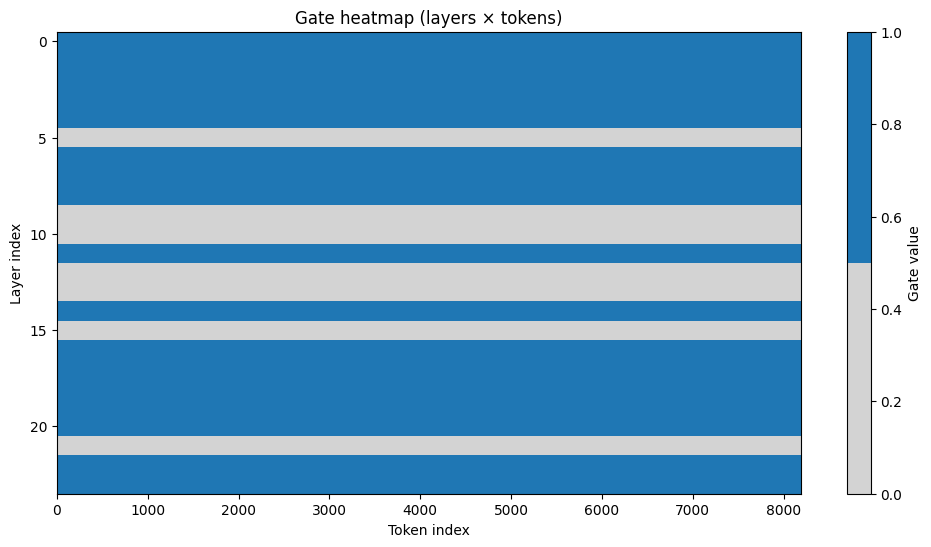

In [19]:
from matplotlib.colors import ListedColormap

sol = solution.detach().cpu().float().numpy().T

plt.figure(figsize=(12, 6))
plt.imshow(sol, aspect="auto", cmap=ListedColormap(['#d3d3d3', '#1f77b4']), interpolation='nearest')
plt.colorbar(label="Gate value")
plt.xlabel("Token index")
plt.ylabel("Layer index")
plt.title("Gate heatmap (layers × tokens)")
plt.show()

(0.0, 22.155)

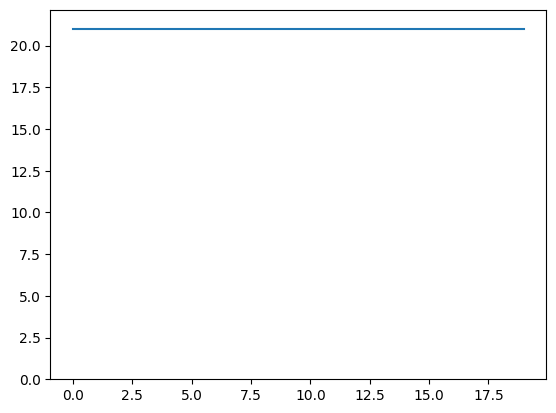

In [20]:
plt.plot(run_info['ppl'])
plt.ylim(bottom=0)

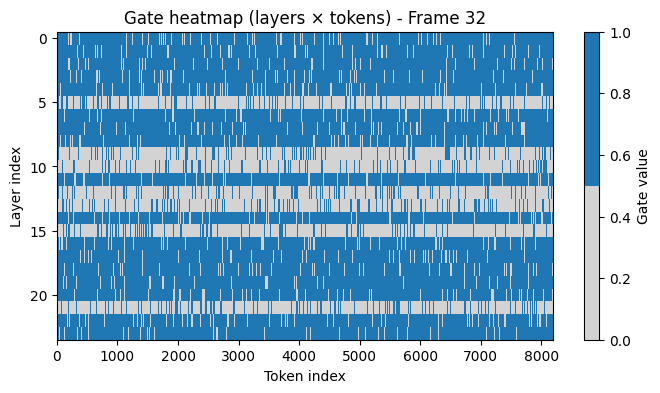

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import ListedColormap
from IPython.display import HTML

# Colormap for binary gates
cmap = ListedColormap(['#d3d3d3', '#1f77b4'])

# Prepare the list of matrices
# matrices = [x.detach().cpu().float().numpy().T for x in run_info['mask']]
matrices = [x.detach().cpu().float().numpy().T for x in population]

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(matrices[0], aspect="auto", cmap=cmap, interpolation='nearest')
ax.set_xlabel("Token index")
ax.set_ylabel("Layer index")
ax.set_title("Gate heatmap (layers × tokens)")
cbar = plt.colorbar(im, ax=ax, label="Gate value")

def update(frame):
    im.set_data(matrices[frame])
    ax.set_title(f"Gate heatmap (layers × tokens) - Frame {frame+1}")
    return [im]

# Create animation
ani = FuncAnimation(fig, update, frames=len(matrices), blit=True)

# Display inline in Jupyter Notebook
HTML(ani.to_jshtml())
